# Figure 7 — Temporal compression in the strong-recoil regime

Light wavelength 1064 nm, field amplitude $E_0=4$ MV/m, optical phase velocity matched to 30 keV electrons
(electrons of other energies are phase-mismatched).

* **(a)** Maximum DOC$_1$ reached during free propagation as a function of kinetic energy and interaction length $L$.
  This map is computed by the standalone script `compute_fig7a_doc_map.py` (a few CPU-hours; see its docstring).
  This notebook only loads its output unless `RECOMPUTE_MAP = True`.
* **(b–f)** Blue cross of (a), $E_{\rm kin}=30.29$ keV, $L=84~\mu$m:
  (b) sideband dynamics up to $1.2L$; (c) sideband distribution at $L$; (d) electron probability density during free
  propagation around the Talbot distance $z_T$; (e) density at the maximum of DOC$_1$; (f) DOC$_1$ versus free-propagation distance.
* **(g–k)** Same for the green cross, $E_{\rm kin}=30.80$ keV, $L=28~\mu$m. Free propagation is shown over
  $0.90$–$1.10\,z_T$ (blue case: $0.99$–$1.01\,z_T$).

Free propagation is described in the frame co-moving with the electron (the rigid time shift $\ell\zeta_{\rm free}$
is removed), so only the recoil phase $\exp(-2\pi i\ell^2 z/z_T)$ acts; the time axis is $\omega t$ over one optical period.

**Data files** (plain-text CSV in `data/fig7/`, see `data/README.md`): one or more files per panel, named after the panel
(`fig7a_DOC1_max.csv`, `fig7b_P.csv`, `fig7c_phi_at_L.csv`, `fig7d_density.csv`, `fig7e_density_at_max.csv`, `fig7f_DOC1.csv`,
and likewise g–k), plus `fig7a_parameters.csv`, `fig7a_per_energy.csv`, `fig7a_zfree_at_max.csv` and
`fig7_blue_parameters.csv`, `fig7_green_parameters.csv`.

In [1]:
import subprocess
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pinem_recoil as pr

DATA = Path("data") / "fig7"
FIGS = Path("figures")
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False       # panels (b)-(k): about a minute
RECOMPUTE_MAP = False   # panel (a): several CPU-hours, runs compute_fig7a_doc_map.py

## Parameters

In [2]:
wavelength = 1064e-9
E0 = 4e6
E_kin_phase_matched = 30e3
d_zeta = 0.1                   # interaction step (converged: same DOC_1 to 1e-4 as d_zeta = 0.05)
truncation_margin = 100        # as in compute_fig7a_doc_map.py
cases = {
    # s_range: free-propagation window in units of the Talbot distance (as in the original scripts)
    "blue":  dict(E_kin=30290.0, L=84e-6, s_range=(0.99, 1.01), panels="bcdef"),
    "green": dict(E_kin=30800.0, L=28e-6, s_range=(0.90, 1.10), panels="ghijk"),
}
interaction_extent = 1.2       # panels (b), (g) extend to 1.2 L
n_s, n_theta = 1000, 1000

v_ph = pr.electron_parameters(E_kin_phase_matched, wavelength, E0)["v"]

## Panel (a): DOC$_1$ map

In [3]:
mapfile = DATA / "fig7a_DOC1_max.csv"
if RECOMPUTE_MAP or not mapfile.exists():
    subprocess.run([sys.executable, "compute_fig7a_doc_map.py", "--out-dir", str(DATA)], check=True)

## Panels (b)–(k)

In [4]:
def compute_case(E_kin, L, s_range):
    p = pr.electron_parameters(E_kin, wavelength, E0)
    a, g = p["a"], p["g"]
    l_max = pr.l_max_estimate(a, g, v_ph / p["v"] - 1) + truncation_margin
    d_phi = -d_zeta * v_ph / p["v"]
    zeta_L = L * p["zeta_per_m"]
    N_L = int(zeta_L / d_zeta)
    # (b) dynamics sampled every 10 steps (Delta zeta = 1) up to 1.2 L, plus the state at exactly N_L steps
    n_traj = np.arange(0, int(interaction_extent * zeta_L / d_zeta) + 1, 10)
    phi = pr.propagate_to(a, g, l_max, d_zeta, d_phi, np.append(n_traj, N_L))
    phi_traj, phi_L = phi[:, :-1], phi[:, -1]
    # (d)-(f) free propagation
    s = np.linspace(*s_range, n_s)
    theta, dens = pr.talbot_carpet(phi_L, s, n_theta)
    doc = pr.doc_from_density(dens)
    print(f"E_kin = {E_kin:.0f} eV, L = {L * 1e6:.0f} um: a = {a:.0f}, g = {g:.3f}, l_max = {l_max}, "
          f"delta_v = {p['v'] / v_ph - 1:+.4f}, z_T = {p['z_T'] * 1e3:.2f} mm, max DOC_1 = {doc.max():.3f}")
    return dict(a=a, g=g, l_max=l_max, d_phi=d_phi, delta_v=p["v"] / v_ph - 1, z_T=p["z_T"],
                zeta_per_m=p["zeta_per_m"], ell=pr.sideband_axis(l_max),
                z_interaction=n_traj * d_zeta / p["zeta_per_m"], P_interaction=np.abs(phi_traj)**2,
                phi_at_L=phi_L, s=s, theta=theta, density=dens, DOC1=doc)


def case_files(name, panels):
    b, c, d, e, f = panels
    return dict(P=DATA / f"fig7{b}_P.csv", phi=DATA / f"fig7{c}_phi_at_L.csv", density=DATA / f"fig7{d}_density.csv",
                cut=DATA / f"fig7{e}_density_at_max.csv", DOC1=DATA / f"fig7{f}_DOC1.csv",
                par=DATA / f"fig7_{name}_parameters.csv")


for name, c in cases.items():
    F = case_files(name, c["panels"])
    if RECOMPUTE or not all(f.exists() for f in F.values()):
        r = compute_case(c["E_kin"], c["L"], c["s_range"])
        i_max = np.argmax(r["DOC1"])
        pr.save_map(F["P"], r["P_interaction"], r["z_interaction"] * 1e6, r["ell"], "z_um", "ell")
        pr.save_columns(F["phi"], fmt="%.17g", ell=r["ell"], phi=r["phi_at_L"], P=np.abs(r["phi_at_L"])**2)
        pr.save_map(F["density"], r["density"], r["s"], r["theta"], "z_free_over_zT", "omega_t")
        pr.save_columns(F["cut"], omega_t=r["theta"], density=r["density"][:, i_max])
        pr.save_columns(F["DOC1"], z_free_over_zT=r["s"], DOC1=r["DOC1"])
        pr.save_parameters(F["par"], [
            ("E_kin_eV", c["E_kin"], "electron kinetic energy"),
            ("L_m", c["L"], "interaction length"),
            ("a", r["a"], "recoil parameter"),
            ("g", r["g"], "coupling strength"),
            ("delta_v", r["delta_v"], "velocity mismatch v/v_ph - 1"),
            ("l_max", r["l_max"], "sideband truncation |l| <= l_max"),
            ("d_zeta", d_zeta, "propagation step"),
            ("d_phi", r["d_phi"], "field-phase step per propagation step (-d_zeta v_ph/v)"),
            ("zeta_per_m", r["zeta_per_m"], "omega/v: zeta per metre"),
            ("z_T_m", r["z_T"], "Talbot distance"),
            ("z_free_at_max_DOC1_over_zT", r["s"][i_max], "free-propagation distance of panels (e)/(j)"),
            ("max_DOC1", r["DOC1"][i_max], "maximum DOC_1 in the window"),
        ])
        print("saved", *F.values())

E_kin = 30290 eV, L = 84 um: a = 113404, g = 0.192, l_max = 711, delta_v = +0.0044, z_T = 39.80 mm, max DOC_1 = 0.618


saved data\fig7\fig7b_P.csv data\fig7\fig7c_phi_at_L.csv data\fig7\fig7d_density.csv data\fig7\fig7e_density_at_max.csv data\fig7\fig7f_DOC1.csv data\fig7\fig7_blue_parameters.csv


E_kin = 30800 eV, L = 28 um: a = 115478, g = 0.193, l_max = 201, delta_v = +0.0121, z_T = 40.84 mm, max DOC_1 = 0.535


saved data\fig7\fig7g_P.csv data\fig7\fig7h_phi_at_L.csv data\fig7\fig7i_density.csv data\fig7\fig7j_density_at_max.csv data\fig7\fig7k_DOC1.csv data\fig7\fig7_green_parameters.csv


## Load data and plot

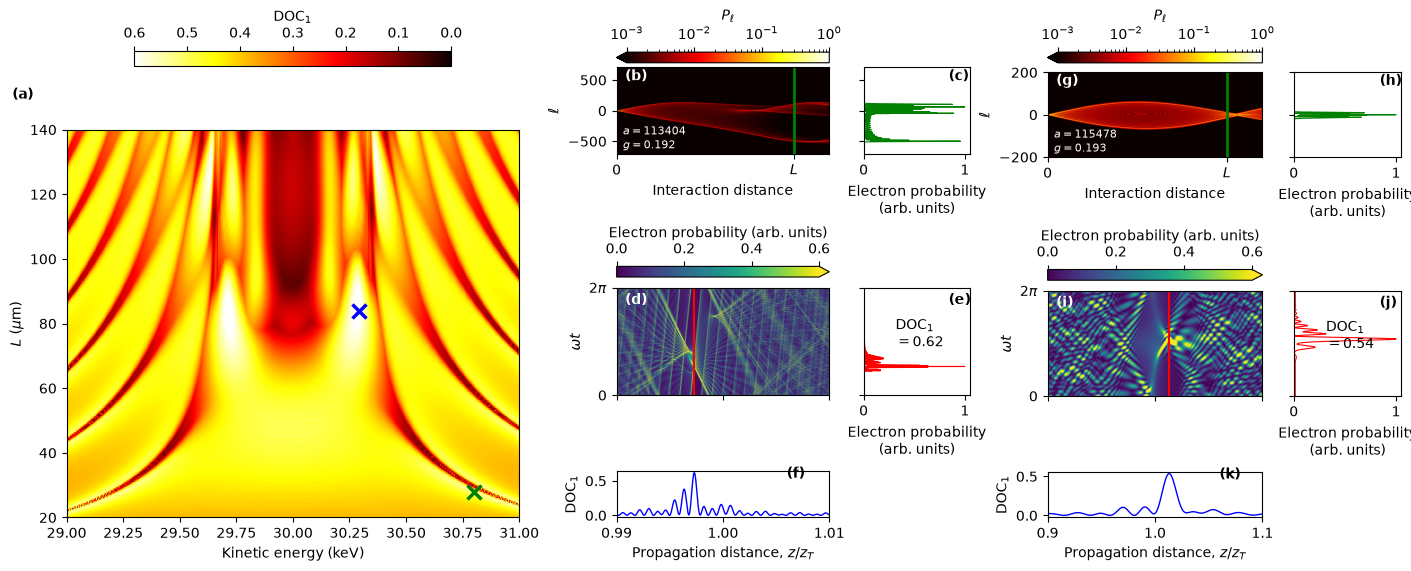

In [5]:
E_map, L_map, DOC_map = pr.load_map(mapfile)          # columns: E_kin (eV), rows: L (um)
B = {}
for name, c in cases.items():
    F = case_files(name, c["panels"])
    D = pr.load_parameters(F["par"])
    z_um, D["ell"], D["P_interaction"] = pr.load_map(F["P"])
    D["z_over_L"] = z_um * 1e-6 / D["L_m"]
    D["phi_at_L"] = pr.load_columns(F["phi"])["phi"]
    D["s_free"], D["omega_t"], D["density"] = pr.load_map(F["density"])
    D["DOC1"] = pr.load_columns(F["DOC1"])["DOC1"]
    B[name] = D

hot = plt.get_cmap("hot").copy(); hot.set_under(hot(0.0)); hot.set_bad(hot(0.0))
fig = plt.figure(figsize=(14, 5.6), constrained_layout=True)
outer = fig.add_gridspec(1, 3, width_ratios=[1.05, 1, 1])

# (a)
ax_a = fig.add_subplot(outer[0])
E, L = E_map / 1e3, L_map
im = ax_a.imshow(DOC_map, origin="lower", aspect="auto", cmap="hot",
                 extent=[E[0], E[-1], L[0], L[-1]], vmin=0, vmax=0.6)
for name, col in [("blue", "b"), ("green", "g")]:
    ax_a.plot(B[name]["E_kin_eV"] / 1e3, B[name]["L_m"] * 1e6, "x", color=col, ms=10, mew=2.5)
ax_a.set_xlabel("Kinetic energy (keV)"); ax_a.set_ylabel(r"$L$ ($\mu$m)")
ax_a.text(-0.12, 1.08, "(a)", transform=ax_a.transAxes, fontweight="bold")
cb = fig.colorbar(im, ax=ax_a, location="top", shrink=0.7)
cb.set_label(r"DOC$_1$"); cb.ax.invert_xaxis()

for k, (name, letters) in enumerate([("blue", "bcdef"), ("green", "ghijk")]):
    D = B[name]
    inner = outer[k + 1].subgridspec(3, 2, width_ratios=[2, 1], height_ratios=[1.3, 1.6, 0.7])
    ax_b = fig.add_subplot(inner[0, 0]); ax_c = fig.add_subplot(inner[0, 1], sharey=ax_b)
    ax_d = fig.add_subplot(inner[1, 0]); ax_e = fig.add_subplot(inner[1, 1], sharey=ax_d)
    ax_f = fig.add_subplot(inner[2, 0], sharex=ax_d)
    ell, zi = D["ell"], D["z_over_L"]
    imb = ax_b.imshow(D["P_interaction"], origin="lower", aspect="auto", cmap=hot, norm=LogNorm(1e-3, 1),
                      extent=[zi[0], zi[-1], ell[0] - 0.5, ell[-1] + 0.5])
    ax_b.axvline(1, color="g", lw=2)
    ax_b.set_xticks([0, 1], ["0", r"$L$"]); ax_b.set_xlabel("Interaction distance"); ax_b.set_ylabel(r"$\ell$")
    ax_b.text(0.03, 0.06, rf"$a={D['a']:.0f}$" + "\n" + rf"$g={D['g']:.3f}$", color="w", transform=ax_b.transAxes, fontsize=8)
    fig.colorbar(imb, ax=ax_b, location="top", extend="min").set_label(r"$P_\ell$")
    P_L = np.abs(D["phi_at_L"])**2
    ax_c.plot(P_L / P_L.max(), ell, "g-", lw=0.8)
    ax_c.set_xlim(0, 1.05); ax_c.tick_params(labelleft=False)
    ax_c.set_xlabel("Electron probability\n(arb. units)")
    s, th, dens, doc = D["s_free"], D["omega_t"], D["density"], D["DOC1"]
    imd = ax_d.imshow(dens, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=0.6,
                      extent=[s[0], s[-1], th[0], th[-1]])
    i_max = np.argmax(doc)
    ax_d.axvline(s[i_max], color="r", lw=1.5)
    ax_d.set_yticks([0, 2 * np.pi], ["0", r"$2\pi$"]); ax_d.set_ylabel(r"$\omega t$")
    ax_d.tick_params(labelbottom=False)
    fig.colorbar(imd, ax=ax_d, location="top", extend="max").set_label("Electron probability (arb. units)")
    ax_e.plot(dens[:, i_max] / dens[:, i_max].max(), th, "r-", lw=0.8)
    ax_e.set_xlim(0, 1.05); ax_e.tick_params(labelleft=False)
    ax_e.text(0.3, 0.45, rf"DOC$_1$" + "\n" + rf"$={doc[i_max]:.2f}$", transform=ax_e.transAxes)
    ax_e.set_xlabel("Electron probability\n(arb. units)")
    ax_f.plot(s, doc, "b-", lw=1)
    ax_f.set_xlabel(r"Propagation distance, $z/z_T$"); ax_f.set_ylabel(r"DOC$_1$")
    ax_f.set_xticks([s[0], 1.0, s[-1]])
    for ax, lab, col in zip([ax_b, ax_c, ax_d, ax_e, ax_f], letters, ["w", "k", "w", "k", "k"]):
        ax.text(0.80 if lab not in "bdgi" else 0.04, 0.85, f"({lab})", color=col, transform=ax.transAxes, fontweight="bold")
fig.savefig(FIGS / "fig7.png", dpi=200)
fig.savefig(FIGS / "fig7.pdf")
plt.show()